In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

zip_path = (
    "/content/drive/MyDrive/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch.zip"
)

extract_dir = "/content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print(os.listdir(extract_dir))

Mounted at /content/drive
['train_labels.csv', 'sample_submission.csv', 'test', 'train']


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

from keras import layers
from sklearn.model_selection import train_test_split

# Dataset paths
dataset_dir = (
    "/content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

label_csv = os.path.join(dataset_dir, "train_labels.csv")
training_images = os.path.join(dataset_dir, "train", "train")

# If the ZIP contains an additional outer folder, locate it
if not os.path.exists(label_csv):
    for root, dirs, files in os.walk(dataset_dir):
        if "train_labels.csv" in files:
            label_csv = os.path.join(root, "train_labels.csv")
            training_images = os.path.join(root, "train", "train")
            break

print("CSV:", label_csv)
print("Training images:", training_images)
print("CSV exists:", os.path.isfile(label_csv))
print("Image folder exists:", os.path.isdir(training_images))

assert os.path.isfile(label_csv), "Could not find train_labels.csv"
assert os.path.isdir(training_images), "Could not find train/train"

# Load labels
df = pd.read_csv(label_csv, dtype={"image_id": str})

class_names = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose",
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df["label"] = df["class"].map(class_to_number)

if df["label"].isna().any():
    unknown = df.loc[df["label"].isna(), "class"].unique()
    raise ValueError(f"Unexpected class labels: {unknown}")

df["label"] = df["label"].astype("int32")

# Build image paths, handling IDs with or without .jpg
def get_image_path(image_id):
    filename = str(image_id)
    if not filename.lower().endswith((".jpg", ".jpeg")):
        filename += ".jpg"
    return os.path.join(training_images, filename)

df["image_path"] = df["image_id"].apply(get_image_path)

missing = df.loc[
    ~df["image_path"].map(os.path.isfile), "image_path"
]

if len(missing):
    raise FileNotFoundError(
        f"{len(missing)} images are missing. Examples:\n"
        + "\n".join(missing.head(5).tolist())
    )

# Stratified 80/20 split: validation comes from training data
train_df, validation_df = train_test_split(
    df,
    test_size=0.20,
    random_state=123,
    stratify=df["label"],
)

print("Total labelled images:", len(df))
print("Training images (80%):", len(train_df))
print("Validation images (20%):", len(validation_df))
print("\nTraining class counts:")
print(train_df["class"].value_counts())
print("\nValidation class counts:")
print(validation_df["class"].value_counts())

CSV: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/train_labels.csv
Training images: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/train/train
CSV exists: True
Image folder exists: True
Total labelled images: 63660
Training images (80%): 50928
Validation images (20%): 12732

Training class counts:
class
CatEye      11107
DogEye       9264
CatMouth     5554
CatFace      5554
CatNose      5553
DogMouth     4632
DogNose      4632
DogFace      4632
Name: count, dtype: int64

Validation class counts:
class
CatEye      2777
DogEye      2316
CatNose     1389
CatMouth    1388
CatFace     1388
DogNose     1158
DogMouth    1158
DogFace     1158
Name: count, dtype: int64


In [ ]:
IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)

    # Keep pixel values in the 0–255 range here.
    # The Xception ImageConverter will preprocess them.
    return image, label

def make_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["image_path"].values,
            dataframe["label"].values,
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=123,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_dataset = make_dataset(train_df, shuffle=True)
validation_dataset = make_dataset(validation_df)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
# Freeze the pretrained backbone
conv_base = keras_hub.models.Backbone.from_preset(
    "xception_41_imagenet",
    trainable=False,
)

# Matching preprocessing for Xception
preprocessor = keras_hub.layers.ImageConverter.from_preset(
    "xception_41_imagenet",
    image_size=IMAGE_SIZE,
)

# Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# Build the model for eight classes
inputs = keras.Input(shape=(180, 180, 3))

x = data_augmentation(inputs)
x = preprocessor(x)
x = conv_base(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax",
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_converter                 │ (None, 180, 180, 3)    │             0 │
│ (ImageConverter)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception_backbone               │ (None, 6, 6, 2048)     │    20,861,480 │
│ (XceptionBackbone)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,388,080 (81.59 MB)

 Trainable params: 21,333,552 (81.38 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [ ]:
# Save to Google Drive storage
save_dir = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/Xception"
)

os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(
    save_dir,
    "xception_best.keras",
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8845 - loss: 0.3630
Epoch 1: val_loss improved from None to 0.11766, saving model to /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 874s 527ms/step - accuracy: 0.9310 - loss: 0.2220 - val_accuracy: 0.9650 - val_loss: 0.1177 - learning_rate: 0.0010
Epoch 2/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.9622 - loss: 0.1206
Epoch 2: val_loss did not improve from 0.11766
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 853s 527ms/step - accuracy: 0.9644 - loss: 0.1152 - val_accuracy: 0.9576 - val_loss: 0.1332 - learning_rate: 0.0010
Epoch 3/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.9697 - loss: 0.0978
Epoch 3: val_loss improved from 0.11766 to 0.08139, saving model to /content/drive/MyDrive/animal_facial_re

In [ ]:
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

final_model_path = os.path.join(
    save_dir,
    f"xception_final_{timestamp}.keras",
)

model.save(final_model_path)

print("Best model:", best_model_path)
print("Final model:", final_model_path)

Best model: /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_best.keras
Final model: /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_final_20261012_044313.keras


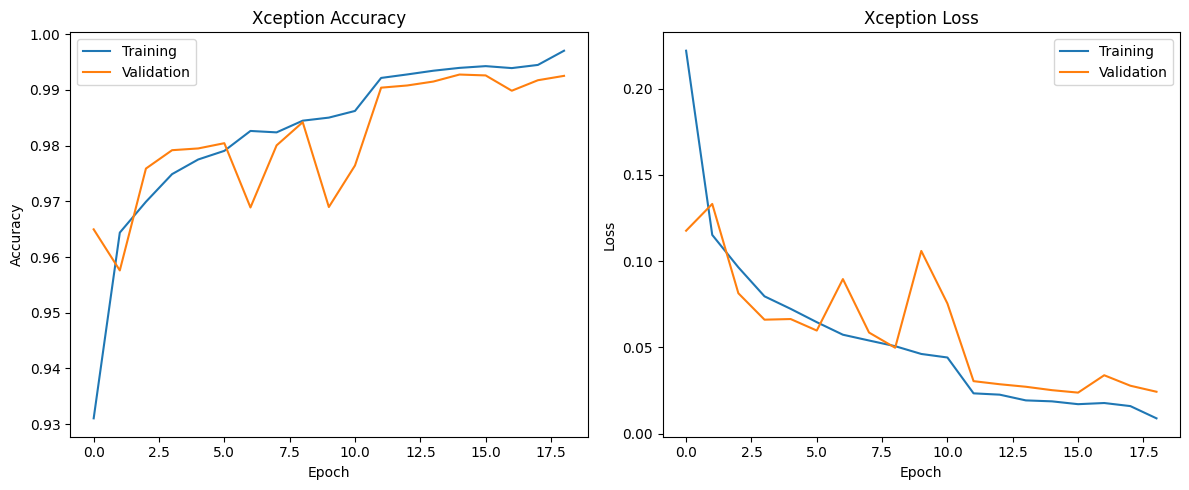

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Xception Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Xception Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

# Path to saved best model
best_model_path = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/"
    "Xception/xception_best.keras"
)

# Path to extracted dataset
dataset_dir = (
    "/content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

# Locate the test/test directory
test_images_dir = None

for root, dirs, files in os.walk(dataset_dir):
    if os.path.basename(root) == "test" and os.path.basename(
        os.path.dirname(root)
    ) == "test":
        test_images_dir = root
        break

if test_images_dir is None:
    raise FileNotFoundError(
        "Could not find test/test. Check the extracted dataset folders."
    )

print("Model exists:", os.path.isfile(best_model_path))
print("Test images directory:", test_images_dir)

assert os.path.isfile(best_model_path), (
    "Best model not found. Check the saved model path."
)

# Import KerasHub before loading the model
model = keras.models.load_model(best_model_path)

model.summary()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model exists: True
Test images directory: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/test/test


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_converter                 │ (None, 180, 180, 3)    │             0 │
│ (ImageConverter)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception_backbone               │ (None, 6, 6, 2048)     │    20,861,480 │
│ (XceptionBackbone)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,055,186 (244.35 MB)

 Trainable params: 21,333,552 (81.38 MB)

 Non-trainable params: 54,528 (213.00 KB)

 Optimizer params: 42,667,106 (162.76 MB)

In [ ]:
from tqdm.auto import tqdm
import os
import numpy as np
import pandas as pd
from PIL import Image

# Set batch size to keep memory usage low
batch_size = 32
image_size = (180, 180)

# Find all test images, including images in subfolders
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
test_image_paths = []
class_names = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose"
]

print("Class names loaded:")
print(class_names)

for root, dirs, files in os.walk(test_images_dir):
    for file in files:
        if file.lower().endswith(image_extensions):
            test_image_paths.append(os.path.join(root, file))

test_image_paths.sort()

total_images = len(test_image_paths)

print(f"Found {total_images} test images.")
print(f"Batch size: {batch_size}")
print("Starting predictions...\n")

results = []

# Progress bar 
for start in tqdm(
    range(0, total_images, batch_size),
    desc="Predicting test images",
    unit="batch"
):
    batch_paths = test_image_paths[start:start + batch_size]
    batch_images = []
    valid_paths = []

    for image_path in batch_paths:
        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize(image_size)
                batch_images.append(np.array(img, dtype=np.float32))
                valid_paths.append(image_path)
        except Exception as e:
            print(f"\nSkipping unreadable image: {image_path}")
            print(f"Reason: {e}")

    if not batch_images:
        continue

    batch_images = np.stack(batch_images, axis=0)

    # Run predictions without displaying output for every image
    predictions = model.predict(batch_images, verbose=0)

    for image_path, prediction in zip(valid_paths, predictions):
        predicted_index = int(np.argmax(prediction))

        results.append({
            "image_id": os.path.basename(image_path),
            "predicted_label": class_names[predicted_index],
            "confidence": float(prediction[predicted_index])
        })

    # Release batch memory before processing the next batch
    del batch_images, predictions

# Save predictions to Google Drive
output_path = (
    "/content/drive/MyDrive/animal_facial_recognition/"
    "xception_test_predictions.csv"
)

predictions_df = pd.DataFrame(results)
predictions_df.to_csv(output_path, index=False)

print("\nPrediction complete!")
print(f"Total test images found: {total_images}")
print(f"Successful predictions: {len(predictions_df)}")
print(f"Results saved to: {output_path}")

display(predictions_df.head())

Class names loaded:
['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']
Found 29443 test images.
Batch size: 32
Starting predictions...



Predicting test images:   0%|          | 0/921 [00:00<?, ?batch/s]


Prediction complete!
Total test images found: 29443
Successful predictions: 29443
Results saved to: /content/drive/MyDrive/animal_facial_recognition/xception_test_predictions.csv


,image_id,predicted_label,confidence
0,00001.jpg,DogEye,0.999998
1,00002.jpg,DogMouth,0.999998
2,00003.jpg,DogNose,1.000000
3,00004.jpg,DogFace,0.999946
4,00005.jpg,CatMouth,0.999993


In [ ]:
prediction_path = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/"
    "xception_test_predictions.csv"
)

os.makedirs(os.path.dirname(prediction_path), exist_ok=True)

results_df.to_csv(prediction_path, index=False)

print("Saved predictions:", prediction_path)
print("Total predictions:", len(results_df))

import matplotlib.pyplot as plt

n = min(12, len(test_image_paths))

plt.figure(figsize=(12, 9))

for i in range(n):
    image = load_img(
        test_image_paths[i],
        target_size=IMAGE_SIZE,
    )

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"{results_df.iloc[i]['predicted_label']}\n"
        f"Confidence: {results_df.iloc[i]['confidence']:.1%}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'results_df' is not defined

FINE TUNING CODE


In [ ]:

import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

from sklearn.model_selection import train_test_split

from google.colab import drive
drive.mount("/content/drive")

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Mounted at /content/drive
TensorFlow: 2.21.0
Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

zip_path = (
    "/content/drive/MyDrive/"
    "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch.zip"
)

dataset_dir = (
    "/content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)


if not os.path.isfile(
    os.path.join(dataset_dir, "train_labels.csv")
):
    os.makedirs(dataset_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(dataset_dir)


label_csv = None
training_images = None

for root, dirs, files in os.walk(dataset_dir):
    if "train_labels.csv" in files:
        label_csv = os.path.join(root, "train_labels.csv")

        candidate = os.path.join(root, "train", "train")
        if os.path.isdir(candidate):
            training_images = candidate
            break

if label_csv is None or training_images is None:
    raise FileNotFoundError(
        "Could not locate train_labels.csv and its train/train folder. "
        "Check the extracted directory structure."
    )

print("Labels:", label_csv)
print("Training images:", training_images)


Labels: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/train_labels.csv
Training images: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/train/train


In [ ]:

class_names = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose",
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df = pd.read_csv(label_csv, dtype={"image_id": str})

df["label"] = df["class"].map(class_to_number)

if df["label"].isna().any():
    raise ValueError(
        "Unexpected class labels: "
        + str(df.loc[df["label"].isna(), "class"].unique())
    )

df["label"] = df["label"].astype("int32")

def get_image_path(image_id):
    filename = str(image_id)

    if not filename.lower().endswith((".jpg", ".jpeg")):
        filename += ".jpg"

    return os.path.join(training_images, filename)

df["image_path"] = df["image_id"].apply(get_image_path)

missing = df.loc[
    ~df["image_path"].map(os.path.isfile),
    "image_path"
]

if len(missing):
    raise FileNotFoundError(
        f"{len(missing)} images are missing. "
        f"Examples: {missing.head(5).tolist()}"
    )

# Recreate the original split.
train_df, validation_df = train_test_split(
    df,
    test_size=0.20,
    random_state=123,
    stratify=df["label"],
)

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(validation_df["class"].value_counts())


Training images: 50928
Validation images: 12732

Training class distribution:
class
CatEye      11107
DogEye       9264
CatMouth     5554
CatFace      5554
CatNose      5553
DogMouth     4632
DogNose      4632
DogFace      4632
Name: count, dtype: int64

Validation class distribution:
class
CatEye      2777
DogEye      2316
CatNose     1389
CatMouth    1388
CatFace     1388
DogNose     1158
DogMouth    1158
DogFace     1158
Name: count, dtype: int64


In [ ]:

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)

    # Keep pixels in the 0-255 range.
    # The loaded model contains the Xception preprocessor.
    return image, label

def make_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["image_path"].values,
            dataframe["label"].values,
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=123,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_dataset = make_dataset(train_df, shuffle=True)
validation_dataset = make_dataset(validation_df)

print("Training and validation datasets are ready.")


Training and validation datasets are ready.


In [ ]:

original_model_path = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/"
    "Xception/xception_best.keras"
)

assert os.path.isfile(original_model_path), (
    f"Saved model not found: {original_model_path}"
)

# Keep KerasHub imported so its custom layers can be deserialized.
model = keras.models.load_model(original_model_path)

model.summary()

print("\nTop-level layers:")
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_converter                 │ (None, 180, 180, 3)    │             0 │
│ (ImageConverter)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception_backbone               │ (None, 6, 6, 2048)     │    20,861,480 │
│ (XceptionBackbone)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,055,186 (244.35 MB)

 Trainable params: 21,333,552 (81.38 MB)

 Non-trainable params: 54,528 (213.00 KB)

 Optimizer params: 42,667,106 (162.76 MB)


Top-level layers:
0 input_layer_1 InputLayer
1 sequential Sequential
2 image_converter ImageConverter
3 xception_backbone XceptionBackbone
4 global_average_pooling2d GlobalAveragePooling2D
5 dense Dense
6 dropout Dropout
7 dense_1 Dense


In [ ]:

# Identify the pretrained backbone inside the saved model.
backbone_candidates = [
    layer
    for layer in model.layers
    if isinstance(layer, keras_hub.models.Backbone)
]

if len(backbone_candidates) != 1:
    raise ValueError(
        "Expected to find one KerasHub Backbone, but found "
        f"{len(backbone_candidates)}. Review model.summary() "
        "and the top-level layer names from Step 5 before continuing."
    )

conv_base = backbone_candidates[0]

print("Backbone:", conv_base.name)
print("Number of backbone layers:", len(conv_base.layers))


Backbone: xception_backbone
Number of backbone layers: 132


In [ ]:

# Unfreeze the backbone first.
conv_base.trainable = True

# Freeze the earlier layers.
# Only the final 20 backbone layers remain eligible for training.
for layer in conv_base.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability.
for layer in conv_base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable backbone layers:")
for layer in conv_base.layers:
    if layer.trainable:
        print(layer.name, type(layer).__name__)

print(
    "\nTrainable weights in complete model:",
    sum(
        int(tf.size(weight).numpy())
        for weight in model.trainable_weights
    ),
)


Trainable backbone layers:
block12_sepconv3_act Activation
block12_sepconv3 SeparableConv2D
block12_residual_add Add
block13_sepconv1_act Activation
block13_sepconv1 SeparableConv2D
block13_sepconv2_act Activation
block13_sepconv2 SeparableConv2D
block13_residual_conv Conv2D
block13_pool MaxPooling2D
block13_residual_add Add
block14_sepconv1 SeparableConv2D
block14_sepconv1_act Activation
block14_sepconv2 SeparableConv2D
block14_sepconv2_act Activation

Trainable weights in complete model: 7838800


In [ ]:

# Baseline evaluation before any fine-tuning updates.
baseline_loss, baseline_accuracy = model.evaluate(
    validation_dataset,
    verbose=1,
)

print(f"Original validation loss: {baseline_loss:.4f}")
print(f"Original validation accuracy: {baseline_accuracy:.4f}")


398/398 ━━━━━━━━━━━━━━━━━━━━ 45s 100ms/step - accuracy: 0.9926 - loss: 0.0238
Original validation loss: 0.0238
Original validation accuracy: 0.9926


In [ ]:

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Model compiled for fine-tuning.")


Model compiled for fine-tuning.


In [ ]:

save_dir = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/Xception"
)

os.makedirs(save_dir, exist_ok=True)

finetuned_best_path = os.path.join(
    save_dir,
    "xception_finetuned_best.keras",
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=finetuned_best_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        mode="min",
        verbose=1,
    ),
]

history_finetune = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

# Save the final in-memory model separately too.
finetuned_final_path = os.path.join(
    save_dir,
    "xception_finetuned_final.keras",
)

model.save(finetuned_final_path)

print("Best fine-tuned model:", finetuned_best_path)
print("Final fine-tuned model:", finetuned_final_path)


Epoch 1/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9954 - loss: 0.0136
Epoch 1: val_loss improved from None to 0.02185, saving model to /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/animal_facial_recognition/saved_models/Xception/xception_finetuned_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 276s 168ms/step - accuracy: 0.9960 - loss: 0.0119 - val_accuracy: 0.9929 - val_loss: 0.0219 - learning_rate: 1.0000e-05
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.9966 - loss: 0.0094
Epoch 2: val_loss did not improve from 0.02185
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 272s 171ms/step - accuracy: 0.9963 - loss: 0.0101 - val_accuracy: 0.9929 - val_loss: 0.0221 - learning_rate: 1.0000e-05
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9965 - loss: 0.0106
Epoch 3: val_loss did not improve from 0.02185

Epoch 3: ReduceLROnPlateau redu

In [ ]:

best_finetuned_model = keras.models.load_model(
    finetuned_best_path
)

finetuned_loss, finetuned_accuracy = (
    best_finetuned_model.evaluate(
        validation_dataset,
        verbose=1,
    )
)

print("\n--- Model comparison ---")
print(
    f"Original validation accuracy:   "
    f"{baseline_accuracy:.4f}"
)
print(
    f"Fine-tuned validation accuracy: "
    f"{finetuned_accuracy:.4f}"
)
print(
    f"Original validation loss:       "
    f"{baseline_loss:.4f}"
)
print(
    f"Fine-tuned validation loss:     "
    f"{finetuned_loss:.4f}"
)

print(
    "Accuracy change (percentage points):",
    round(
        (finetuned_accuracy - baseline_accuracy) * 100,
        2,
    ),
)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 318 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


398/398 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9929 - loss: 0.0219

--- Model comparison ---
Original validation accuracy:   0.9926
Fine-tuned validation accuracy: 0.9929
Original validation loss:       0.0238
Fine-tuned validation loss:     0.0219
Accuracy change (percentage points): 0.02


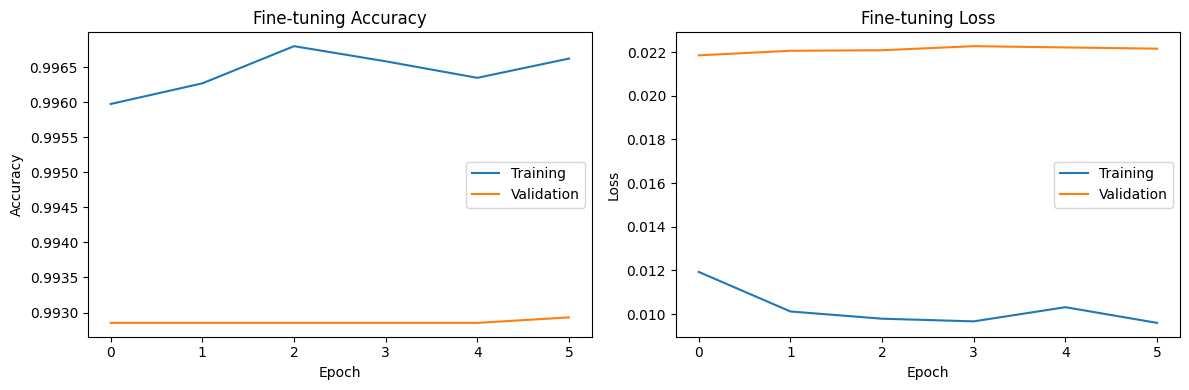

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_finetune.history["accuracy"],
    label="Training",
)
axes[0].plot(
    history_finetune.history["val_accuracy"],
    label="Validation",
)
axes[0].set_title("Fine-tuning Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    history_finetune.history["loss"],
    label="Training",
)
axes[1].plot(
    history_finetune.history["val_loss"],
    label="Validation",
)
axes[1].set_title("Fine-tuning Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
best_model_path = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/"
    "Xception/xception_best.keras"
)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

# Path to saved best model
best_model_path = (
    "/content/drive/MyDrive/"
    "animal_facial_recognition/saved_models/"
    "Xception/xception_finetuned_final.keras"
)

# Path to extracted dataset
dataset_dir = (
    "/content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)


zip_path = (
    "/content/drive/MyDrive/"
    "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch.zip"
)

if not os.path.exists(dataset_dir) or not os.listdir(dataset_dir):
    print("Dataset directory not found or empty. Extracting zip from Drive...")
    os.makedirs(dataset_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(dataset_dir)
    print("Extraction complete.")

# Locate the test/test directory
test_images_dir = None

for root, dirs, files in os.walk(dataset_dir):
    if os.path.basename(root) == "test" and os.path.basename(
        os.path.dirname(root)
    ) == "test":
        test_images_dir = root
        break

if test_images_dir is None:
    raise FileNotFoundError(
        "Could not find test/test. Check the extracted dataset folders."
    )

print("Model exists:", os.path.isfile(best_model_path))
print("Test images directory:", test_images_dir)

assert os.path.isfile(best_model_path), (
    "Best model not found. Check the saved model path."
)

# Import KerasHub before loading the model
model = keras.models.load_model(best_model_path)

model.summary()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset directory not found or empty. Extracting zip from Drive...
Extraction complete.
Model exists: True
Test images directory: /content/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/test/test


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 318 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_converter                 │ (None, 180, 180, 3)    │             0 │
│ (ImageConverter)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception_backbone               │ (None, 6, 6, 2048)     │    20,861,480 │
│ (XceptionBackbone)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,055,186 (244.35 MB)

 Trainable params: 21,333,552 (81.38 MB)

 Non-trainable params: 54,528 (213.00 KB)

 Optimizer params: 42,667,106 (162.76 MB)

In [ ]:
from tqdm.auto import tqdm
import os
import numpy as np
import pandas as pd
from PIL import Image

# Set batch size to keep memory usage low
batch_size = 32
image_size = (180, 180)

# Find all test images, including images in subfolders
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
test_image_paths = []
class_names = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose"
]

print("Class names loaded:")
print(class_names)

for root, dirs, files in os.walk(test_images_dir):
    for file in files:
        if file.lower().endswith(image_extensions):
            test_image_paths.append(os.path.join(root, file))

test_image_paths.sort()

total_images = len(test_image_paths)

print(f"Found {total_images} test images.")
print(f"Batch size: {batch_size}")
print("Starting predictions...\n")

results = []

# Progress bar
for start in tqdm(
    range(0, total_images, batch_size),
    desc="Predicting test images",
    unit="batch"
):
    batch_paths = test_image_paths[start:start + batch_size]
    batch_images = []
    valid_paths = []

    for image_path in batch_paths:
        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize(image_size)
                batch_images.append(np.array(img, dtype=np.float32))
                valid_paths.append(image_path)
        except Exception as e:
            print(f"\nSkipping unreadable image: {image_path}")
            print(f"Reason: {e}")

    if not batch_images:
        continue

    batch_images = np.stack(batch_images, axis=0)

    # Run predictions without displaying output for every image
    predictions = model.predict(batch_images, verbose=0)

    for image_path, prediction in zip(valid_paths, predictions):
        predicted_index = int(np.argmax(prediction))

        results.append({
            "image_id": os.path.basename(image_path),
            "predicted_label": class_names[predicted_index],
            "confidence": float(prediction[predicted_index])
        })

    # Release batch memory before processing the next batch
    del batch_images, predictions

# Save predictions to Google Drive
output_path = (
    "/content/drive/MyDrive/animal_facial_recognition/"
    "xception_finetune_test_predictions.csv"
)

predictions_df = pd.DataFrame(results)
predictions_df.to_csv(output_path, index=False)

print("\nPrediction complete!")
print(f"Total test images found: {total_images}")
print(f"Successful predictions: {len(predictions_df)}")
print(f"Results saved to: {output_path}")

display(predictions_df.head())

Class names loaded:
['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']
Found 29443 test images.
Batch size: 32
Starting predictions...



Predicting test images:   0%|          | 0/921 [00:00<?, ?batch/s]


Prediction complete!
Total test images found: 29443
Successful predictions: 29443
Results saved to: /content/drive/MyDrive/animal_facial_recognition/xception_finetune_test_predictions.csv


,image_id,predicted_label,confidence
0,00001.jpg,DogEye,0.999999
1,00002.jpg,DogMouth,1.000000
2,00003.jpg,DogNose,1.000000
3,00004.jpg,DogFace,0.999992
4,00005.jpg,CatMouth,1.000000
